# Machine Learning for Business – CA1
## Metro Interstate Traffic Volume Dataset

In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("Metro_Interstate_Traffic_Volume.csv.gz")

# Display the first five rows
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [3]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (48204, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB

Missing values:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traff

## 2. Data Cleaning and Preprocessing

In this section, I will check the dataset for missing values and duplicate records. I will also prepare the date column for further analysis.

In [4]:
# Check duplicate records
duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)

Number of duplicate records: 17


In [5]:
# Check holiday values
print(df['holiday'].value_counts(dropna=False))

holiday
NaN                          48143
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64


In [6]:
# Convert date_time to datetime format
df['date_time'] = pd.to_datetime(df['date_time'])

# Check the date range
print("Start date:", df['date_time'].min())
print("End date:", df['date_time'].max())

# Check the updated data type
print("Date column type:", df['date_time'].dtype)

Start date: 2012-10-02 09:00:00
End date: 2018-09-30 23:00:00
Date column type: datetime64[ns]


## 3. Data Cleaning

In this step, I will handle missing values and duplicate records to prepare the dataset for further analysis.

In [7]:
# Replace missing holiday values
df['holiday'] = df['holiday'].fillna('None')

# Check the results
print(df['holiday'].value_counts())

holiday
None                         48143
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64


In [8]:
# Check missing values after cleaning
print("Missing values after cleaning:")
print(df.isnull().sum())

# Check dataset dimensions
print("\nFinal dataset shape:", df.shape)

Missing values after cleaning:
holiday                0
temp                   0
rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
date_time              0
traffic_volume         0
dtype: int64

Final dataset shape: (48204, 9)


In [9]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Check the dataset after removing duplicates
print("Dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape: (48187, 9)
Remaining duplicates: 0


In [10]:
# Check repeated timestamps
repeated_dates = df['date_time'].duplicated().sum()

print("Repeated timestamps:", repeated_dates)

Repeated timestamps: 7612


In [11]:
# Final data quality check
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

Dataset shape: (48187, 9)
Missing values: 0
Duplicate records: 0


## 4. Feature Engineering

In this section, I will create new features from the date and time column to better understand traffic patterns during different hours, days and months.

In [12]:
# Extract date and time features
df['hour'] = df['date_time'].dt.hour
df['day_of_week'] = df['date_time'].dt.dayofweek
df['month'] = df['date_time'].dt.month

# Identify weekends
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

# Display the updated dataset
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,hour,day_of_week,month,is_weekend
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,9,1,10,0
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,10,1,10,0
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,11,1,10,0
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,12,1,10,0
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,13,1,10,0


## 5. Clustering Analysis

In this section, I will use clustering to identify different traffic patterns based on traffic volume, weather conditions and time-related features.

In [13]:
# Select numerical features for clustering
clustering_features = [
    'traffic_volume',
    'temp',
    'rain_1h',
    'snow_1h',
    'clouds_all',
    'hour',
    'day_of_week',
    'month'
]

X = df[clustering_features].copy()

# Check selected features
print("Clustering dataset shape:", X.shape)
X.head()

Clustering dataset shape: (48187, 8)


,traffic_volume,temp,rain_1h,snow_1h,clouds_all,hour,day_of_week,month
0,5545,288.28,0.0,0.0,40,9,1,10
1,4516,289.36,0.0,0.0,75,10,1,10
2,4767,289.58,0.0,0.0,90,11,1,10
3,5026,290.13,0.0,0.0,90,12,1,10
4,4918,291.14,0.0,0.0,75,13,1,10


In [14]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Standardise clustering features
X_scaled = scaler.fit_transform(X)

# Check the result
print("Scaled dataset shape:", X_scaled.shape)
print("First five rows:")
print(X_scaled[:5])

Scaled dataset shape: (48187, 8)
First five rows:
[[ 1.15020531  0.53041592 -0.00746445 -0.02723315 -0.24004863 -0.34548099
  -0.98947829  1.02779521]
 [ 0.63232194  0.61138394 -0.00746445 -0.02723315  0.65704665 -0.20139502
  -0.98947829  1.02779521]
 [ 0.75864723  0.62787742 -0.00746445 -0.02723315  1.04151605 -0.05730906
  -0.98947829  1.02779521]
 [ 0.88899883  0.66911114 -0.00746445 -0.02723315  1.04151605  0.08677691
  -0.98947829  1.02779521]
 [ 0.83464372  0.74483123 -0.00746445 -0.02723315  0.65704665  0.23086287
  -0.98947829  1.02779521]]


In [15]:
# Check for possible outliers in clustering features

X.describe().round(2)

,traffic_volume,temp,rain_1h,snow_1h,clouds_all,hour,day_of_week,month
count,48187.00,48187.00,48187.00,48187.00,48187.00,48187.00,48187.00,48187.00
mean,3259.62,281.20,0.33,0.00,49.37,11.40,2.98,6.51
std,1986.95,13.34,44.80,0.01,39.02,6.94,2.01,3.40
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
25%,1192.50,272.16,0.00,0.00,1.00,5.00,1.00,4.00
50%,3379.00,282.45,0.00,0.00,64.00,11.00,3.00,7.00
75%,4933.00,291.81,0.00,0.00,90.00,17.00,5.00,9.00
max,7280.00,310.07,9831.30,0.51,100.00,23.00,6.00,12.00


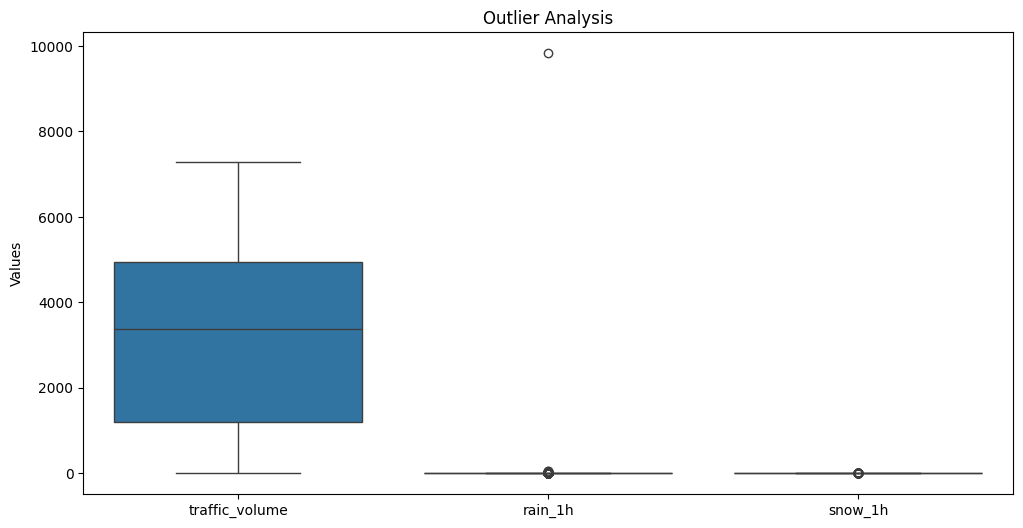

In [16]:
# Visualise possible outliers

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(data=X[['traffic_volume', 'rain_1h', 'snow_1h']])

plt.title('Outlier Analysis')
plt.ylabel('Values')
plt.show()

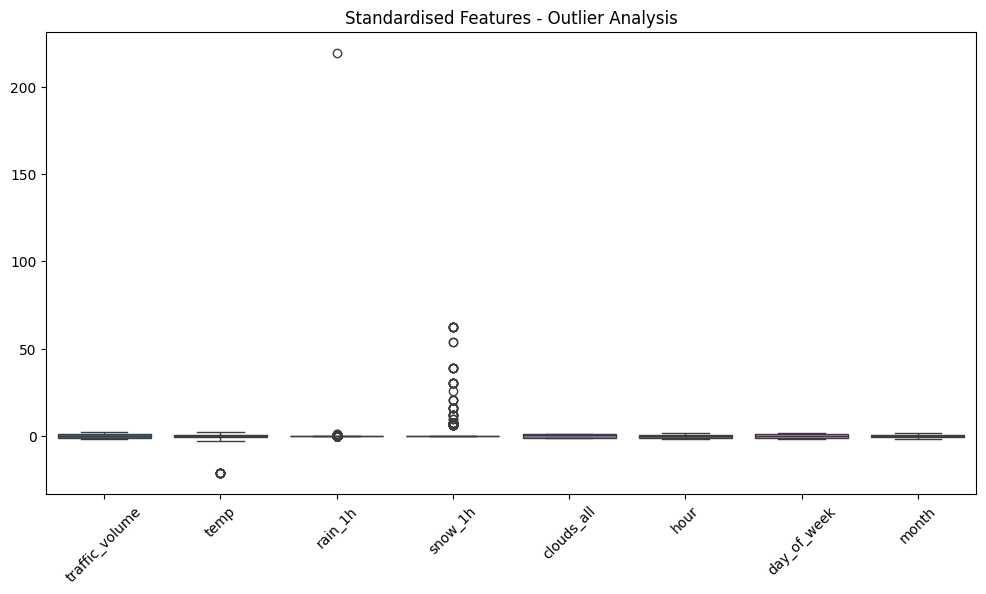

In [17]:
# Compare standardised features

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features
)

plt.figure(figsize=(12, 6))

sns.boxplot(data=X_scaled_df)

plt.title('Standardised Features - Outlier Analysis')
plt.xticks(rotation=45)
plt.show()

In [18]:
# Check extreme values in weather variables

weather_features = ['temp', 'rain_1h', 'snow_1h']

for feature in weather_features:
    print(f"\nFeature: {feature}")
    print("Minimum:", df[feature].min())
    print("Maximum:", df[feature].max())
    print("99th percentile:", df[feature].quantile(0.99))


Feature: temp
Minimum: 0.0
Maximum: 310.07
99th percentile: 302.8228

Feature: rain_1h
Minimum: 0.0
Maximum: 9831.3
99th percentile: 3.271399999999994

Feature: snow_1h
Minimum: 0.0
Maximum: 0.51
99th percentile: 0.0


In [19]:
# Check suspicious weather values

print("Temperature equal to zero:", (df['temp'] == 0).sum())

print("Rain above 100 mm:", (df['rain_1h'] > 100).sum())

print("Snow above zero:", (df['snow_1h'] > 0).sum())

Temperature equal to zero: 10
Rain above 100 mm: 1
Snow above zero: 63


### 5.1 Handling Outliers

I found some unusual values in the weather data, including zero temperatures and very high rainfall. I will treat these values before applying clustering.

In [20]:
# Create a copy for clustering
df_clustering = df.copy()

# Replace invalid temperatures with missing values
df_clustering.loc[df_clustering['temp'] == 0, 'temp'] = float('nan')

# Replace the suspicious rainfall value
df_clustering.loc[df_clustering['rain_1h'] > 100, 'rain_1h'] = float('nan')

# Fill missing values using the median
df_clustering['temp'] = df_clustering['temp'].fillna(
    df_clustering['temp'].median()
)

df_clustering['rain_1h'] = df_clustering['rain_1h'].fillna(
    df_clustering['rain_1h'].median()
)

# Check the results
print("Missing values:", df_clustering.isnull().sum().sum())
print("Minimum temperature:", df_clustering['temp'].min())
print("Maximum rainfall:", df_clustering['rain_1h'].max())

Missing values: 0
Minimum temperature: 243.39
Maximum rainfall: 55.63


In [21]:
# Select the cleaned features for clustering
X = df_clustering[clustering_features].copy()

# Standardise the cleaned data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Check the results
print("Clustering dataset shape:", X.shape)
print("Scaled dataset shape:", X_scaled.shape)
print("Missing values:", X.isnull().sum().sum())

Clustering dataset shape: (48187, 8)
Scaled dataset shape: (48187, 8)
Missing values: 0


In [22]:
# Check standardised features

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features
)

print("Feature means:")
print(X_scaled_df.mean().round(2))

print("\nFeature standard deviations:")
print(X_scaled_df.std(ddof=0).round(2))

Feature means:
traffic_volume   -0.0
temp             -0.0
rain_1h          -0.0
snow_1h           0.0
clouds_all        0.0
hour             -0.0
day_of_week       0.0
month            -0.0
dtype: float64

Feature standard deviations:
traffic_volume    1.0
temp              1.0
rain_1h           1.0
snow_1h           1.0
clouds_all        1.0
hour              1.0
day_of_week       1.0
month             1.0
dtype: float64


### 5.2 K-Means Clustering

In this section, I will use K-Means to identify groups with similar traffic patterns. I will test different numbers of clusters to find a suitable value of K.

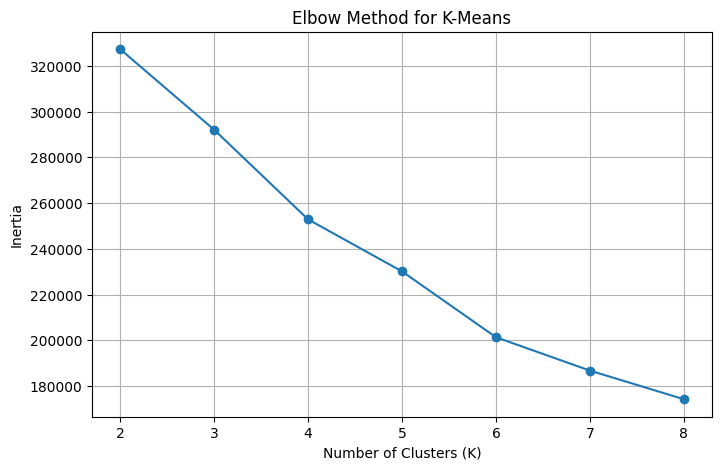

In [23]:
# Import K-Means
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Test different numbers of clusters
inertia_values = []

k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia_values, marker='o')

plt.title('Elbow Method for K-Means')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

In [24]:
# Evaluate different numbers of clusters

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in [3, 4, 5]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=5000,
        random_state=42
    )

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 3, Silhouette Score = 0.1966
K = 4, Silhouette Score = 0.1966
K = 5, Silhouette Score = 0.1932


In [25]:
# Apply K-Means with 4 clusters

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Fit the model
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Add cluster labels to the cleaned dataset
df_clustering['cluster'] = cluster_labels

# Check the number of records in each cluster
print("Number of records per cluster:")
print(df_clustering['cluster'].value_counts().sort_index())

Number of records per cluster:
cluster
0    11342
1    23277
2    13545
3       23
Name: count, dtype: int64


In [26]:
# Check average values for each cluster

cluster_summary = df_clustering.groupby('cluster')[
    clustering_features
].mean().round(2)

print("Average feature values by cluster:")
display(cluster_summary)

Average feature values by cluster:


,traffic_volume,temp,rain_1h,snow_1h,clouds_all,hour,day_of_week,month
cluster,,,,,,,,
0,4062.82,270.38,0.03,0.00,58.87,14.24,2.83,2.51
1,4266.15,287.55,0.16,0.00,48.26,14.87,2.85,8.31
2,857.38,279.60,0.16,0.00,43.25,3.04,3.35,6.74
3,3224.87,271.86,0.17,0.34,90.00,14.52,2.04,8.65
